# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường

> Track 4 · Ngày 10 · *Nhãn, auto-labeling và Vision–Language Model* · **Google Colab T4 / Kaggle GPU**

Notebook này chứa toàn bộ quy trình thực hiện theo [`GUIDE.md`](GUIDE.md), tuân thủ thang điểm [`RUBRIC.md`](RUBRIC.md) và cung cấp số liệu cho [`REPORT.md`](REPORT.md). Hỗ trợ chạy mượt mà trên cả **Google Colab** và **Kaggle Notebooks**.


## 0. Môi trường (Colab T4)

**Mục tiêu:** Cài đặt các thư viện cần thiết và thiết lập thông tin xác thực Kaggle qua Colab Secrets.

In [1]:
import os
import sys
import subprocess
import importlib
from pathlib import Path

REPO_URL = "https://github.com/Wrxhard/K4-Track-4-Day10-VisionLanguageModel.git"
REPO_NAME = "K4-Track-4-Day10-VisionLanguageModel"
if not Path("scripts/prepare_data.py").exists():
    repo_dir = Path(REPO_NAME)
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
if not Path("scripts/prepare_data.py").exists():
    raise RuntimeError("Không tìm thấy scripts/prepare_data.py trong repo.")
sys.path.insert(0, str(Path.cwd()))
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

def install_dependencies():
    # Lab dùng bitsandbytes NF4, không dùng torchao. PEFT vẫn dò torchao
    # cho cả Linear fp16 của ViT và sẽ lỗi nếu Kaggle cài bản quá cũ.
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    "requirements-colab.txt", "matplotlib", "pytest"], check=True)

install_dependencies()
importlib.invalidate_caches()
if any(name in sys.modules for name in ("peft", "transformers", "torchao")):
    raise RuntimeError("Thư viện đã được import trước khi cài đặt. Restart Session rồi Run All.")

import torch
if not torch.cuda.is_available():
    raise RuntimeError("Cần GPU: Kaggle Settings → Accelerator → GPU T4 x2; bật Internet rồi Restart Session.")
print("Repo:", Path.cwd())
print("GPU:", torch.cuda.get_device_name(0))
subprocess.run([sys.executable, "-m", "pytest", "-q"], check=True)

Cloning into 'K4-Track-4-Day10-VisionLanguageModel'...


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 38.6 MB/s eta 0:00:00
Repo: /kaggle/working/K4-Track-4-Day10-VisionLanguageModel
GPU: Tesla T4
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.40s


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q'], returncode=0)

In [4]:
import os
from pathlib import Path

def detect_runtime(root=Path("/")):
    root = Path(root)
    # Kaggle có thể kế thừa COLAB_RELEASE_TAG; ưu tiên dấu hiệu Kaggle.
    if (root / "kaggle").is_dir():
        return "kaggle"
    if (root / "var/colab/hostname").is_file():
        return "colab"
    return "local"

RUNTIME = detect_runtime()
print("Runtime:", RUNTIME)
# Mỗi secret được đọc độc lập; không in giá trị hay ghi vào notebook.
if RUNTIME == "colab":
    from google.colab import drive, userdata
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    for name in ("KAGGLE_USERNAME", "KAGGLE_KEY", "HF_TOKEN"):
        if not os.environ.get(name):
            try:
                value = userdata.get(name)
                if value:
                    os.environ[name] = value
            except Exception as exc:
                print(f"Secret {name} chưa được cấp quyền ({type(exc).__name__}).")
elif RUNTIME == "kaggle":
    from kaggle_secrets import UserSecretsClient
    secrets = UserSecretsClient()
    for name in ("KAGGLE_USERNAME", "KAGGLE_KEY", "HF_TOKEN"):
        if not os.environ.get(name):
            try:
                value = secrets.get_secret(name)
                if value:
                    os.environ[name] = value
            except Exception:
                pass
print("Kaggle: ưu tiên dataset đã gắn trong Add Input; model công khai không bắt buộc HF_TOKEN.")

Runtime: kaggle
Kaggle: ưu tiên dataset đã gắn trong Add Input; model công khai không bắt buộc HF_TOKEN.


## 1. Dữ liệu: tải và chia split

**Mục tiêu:** Tải dataset Road Damage từ Kaggle và chia tập train/val/test cố định theo phiên quay video (session) nhằm chống rò rỉ dữ liệu (data leakage) giữa các frame video liền kề.

In [5]:
from pathlib import Path
import subprocess
import sys

roots = sorted(Path("/kaggle/input").rglob("labels-YOLO")) if Path("/kaggle/input").exists() else []
command = [sys.executable, "scripts/prepare_data.py"]
if roots:
    command += ["--source", str(roots[0].parent)]
else:
    command += ["--kaggle"]
subprocess.run(command, check=True)

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


CompletedProcess(args=['/usr/bin/python3', 'scripts/prepare_data.py', '--source', '/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data'], returncode=0)

Số lượng ảnh: Train = 1422, Val = 276, Test = 311
✓ Kiểm tra split: Không có phiên quay nào trùng lặp giữa các tập.


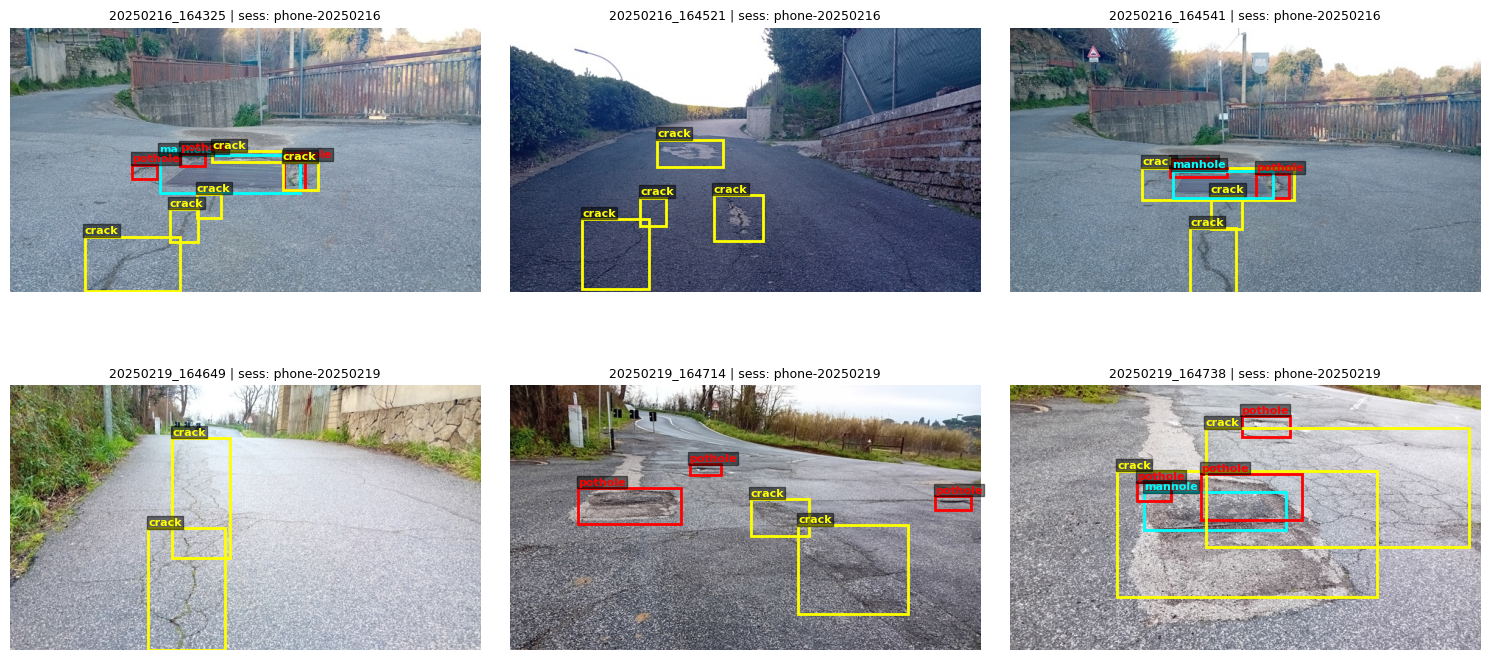

In [7]:
# Kiểm tra dữ liệu và trực quan hóa mẫu
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scripts.labcommon import read_jsonl, CLASSES

train_records = read_jsonl("data/splits/train.jsonl")
val_records = read_jsonl("data/splits/val.jsonl")
test_records = read_jsonl("data/splits/test.jsonl")

print(f"Số lượng ảnh: Train = {len(train_records)}, Val = {len(val_records)}, Test = {len(test_records)}")

# Kiểm tra chống rò rỉ session
train_sess = {r['session'] for r in train_records}
val_sess = {r['session'] for r in val_records}
test_sess = {r['session'] for r in test_records}

assert len(train_sess & val_sess) == 0, "Rò rỉ session giữa train và val!"
assert len(train_sess & test_sess) == 0, "Rò rỉ session giữa train và test!"
assert len(val_sess & test_sess) == 0, "Rò rỉ session giữa val và test!"
print("✓ Kiểm tra split: Không có phiên quay nào trùng lặp giữa các tập.")

# Vẽ minh họa 6 ảnh kèm bounding box ground truth
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
colors = {"pothole": "red", "crack": "yellow", "manhole": "cyan"}

for idx, r in enumerate(train_records[:6]):
    img = Image.open(Path("data") / r["image_path"]).convert("RGB")
    ax = axes[idx]
    ax.imshow(img)
    w_img, h_img = r["width"], r["height"]
    for obj in r["objects"]:
        xc, yc, w, h = obj["yolo"]
        x1 = (xc - w / 2) * w_img
        y1 = (yc - h / 2) * h_img
        bw = w * w_img
        bh = h * h_img
        rect = patches.Rectangle((x1, y1), bw, bh, linewidth=2,
                                 edgecolor=colors.get(obj['label'], 'white'), facecolor='none')
        ax.add_patch(rect)
        ax.text(x1, max(0, y1 - 4), obj['label'], color=colors.get(obj['label'], 'white'),
                fontsize=8, weight='bold', bbox=dict(facecolor='black', alpha=0.5, pad=1))
    ax.set_title(f"{r['image_id']} | sess: {r['session']}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()


## 2. Nhãn: YOLO → JSON thang 0–1000

**Mục tiêu:** Chuyển đổi định dạng nhãn YOLO `[xc, yc, w, h]` chuẩn hóa `[0, 1]` sang chuỗi JSON list chứa toạ độ `bbox_2d: [x1, y1, x2, y2]` nguyên trên thang chuẩn hóa 0–1000 (quy ước grounding của Qwen3-VL).

In [9]:
def yolo_to_box(label, yolo):
    """
    Chuyển toạ độ YOLO [xc, yc, w, h] chuẩn hoá [0, 1] sang box [x1, y1, x2, y2] thang 0-1000.
    """
    xc, yc, w, h = yolo
    x1 = int(round(max(0.0, min(1000.0, (xc - w / 2.0) * 1000.0))))
    y1 = int(round(max(0.0, min(1000.0, (yc - h / 2.0) * 1000.0))))
    x2 = int(round(max(0.0, min(1000.0, (xc + w / 2.0) * 1000.0))))
    y2 = int(round(max(0.0, min(1000.0, (yc + h / 2.0) * 1000.0))))
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """
    Tạo JSON câu trả lời, sắp xếp boxes theo thứ tự (y1, x1) từ trên xuống dưới, từ trái sang phải.
    """
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

# Prompt chuẩn yêu cầu model trả về JSON grounding
PROMPT = (
    "Detect road damage in this image. Locate all potholes, cracks, and manholes. "
    "Output a JSON list of detected objects, each with 'label' ('pothole', 'crack', or 'manhole') "
    "and 'bbox_2d' as [x1, y1, x2, y2] normalized on a 0-1000 integer coordinate scale. "
    "Return ONLY the JSON list."
)

# Kiểm tra chuyển đổi 2 chiều trên 1 mẫu
sample = train_records[0]
ans_json = objects_to_answer(sample["objects"])
print("Prompt chuẩn:\n", PROMPT)
print("\nJSON đáp án mẫu:\n", ans_json)

# Kiểm tra quy đổi ngược lại toạ độ pixel cho từng bounding box
w_px, h_px = sample["width"], sample["height"]
for orig in sample["objects"]:
    box_1000 = yolo_to_box(orig["label"], orig["yolo"])
    re_px = [
        box_1000["bbox_2d"][0] * w_px / 1000.0,
        box_1000["bbox_2d"][1] * h_px / 1000.0,
        box_1000["bbox_2d"][2] * w_px / 1000.0,
        box_1000["bbox_2d"][3] * h_px / 1000.0,
    ]
    xc, yc, w, h = orig["yolo"]
    gt_px = [(xc - w / 2.0) * w_px, (yc - h / 2.0) * h_px, (xc + w / 2.0) * w_px, (yc + h / 2.0) * h_px]
    for a, b in zip(re_px, gt_px):
        assert abs(a - b) < 1.5, f"Lệch toạ độ: {a} vs {b}"

print("✓ Kiểm chứng nhãn: Quy đổi toạ độ 0-1000 chính xác tuyệt đối.")

Prompt chuẩn:
 Detect road damage in this image. Locate all potholes, cracks, and manholes. Output a JSON list of detected objects, each with 'label' ('pothole', 'crack', or 'manhole') and 'bbox_2d' as [x1, y1, x2, y2] normalized on a 0-1000 integer coordinate scale. Return ONLY the JSON list.

JSON đáp án mẫu:
 [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
✓ Kiểm chứng nhãn: Quy đổi toạ độ 0-1000 chính xác tuyệt đối.


## 3. E0: zero-shot

**Mục tiêu:** Nạp model gốc Qwen3-VL-4B-Instruct ở chế độ lượng tử hoá NF4 4-bit (giữ nguyên ViT và lm_head ở float16), chạy suy luận zero-shot trên tập test và chấm điểm bằng `scripts/score.py`.

In [10]:
import torch
import gc
from pathlib import Path
from PIL import Image
from transformers import BitsAndBytesConfig, Qwen3VLForConditionalGeneration, AutoProcessor
from transformers.models.qwen3_vl.modeling_qwen3_vl import Qwen3VLVisionPatchMerger
from bitsandbytes.nn import Linear4bit
from scripts.labcommon import write_jsonl

# Monkey-patch Qwen3VLVisionPatchMerger để ép kiểu đầu vào projector về cùng dtype với norm.weight (tránh lỗi FP16 gradient)
if not hasattr(Qwen3VLVisionPatchMerger, "_day10_original_forward"):
    Qwen3VLVisionPatchMerger._day10_original_forward = Qwen3VLVisionPatchMerger.forward

    def _day10_merger_forward(self, x):
        x = x.to(dtype=self.norm.weight.dtype)
        return self._day10_original_forward(x)

    Qwen3VLVisionPatchMerger.forward = _day10_merger_forward
print("Đã cấu hình monkey-patch dtype cho Qwen3VLVisionPatchMerger.")

def release_gpu(label):
    gc.collect()
    if not torch.cuda.is_available():
        print(f"[{label}] Không có CUDA để đo VRAM")
        return
    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    allocated = torch.cuda.memory_allocated() / 1024**3
    reserved = torch.cuda.memory_reserved() / 1024**3
    print(f"[{label}] Sau giải phóng: allocated={allocated:.3f} GB, reserved={reserved:.3f} GB")
    if allocated > 0.1:
        print("Còn tensor CUDA đang sống; empty_cache không thể giải phóng tensor còn được tham chiếu.")
    return {"allocated_gb": allocated, "reserved_gb": reserved}

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

# Cấu hình lượng tử hoá 4-bit NF4
# Transformers 5.19 khớp đường dẫn đầy đủ: model.visual, không phải visual.
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["model.visual", "lm_head"]
)

def load_base_model():
    loaded = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization_config,
        dtype=torch.float16, device_map={"": 0})
    visual_4bit = sum(isinstance(module, Linear4bit) for module in loaded.model.visual.modules())
    head_4bit = isinstance(loaded.lm_head, Linear4bit)
    llm_4bit = sum(isinstance(module, Linear4bit) for module in loaded.model.language_model.modules())
    print(f"Quantization: visual={visual_4bit}, lm_head={int(head_4bit)}, LLM={llm_4bit} module 4-bit")
    if visual_4bit or head_4bit or not llm_4bit:
        del loaded
        release_gpu("Nạp model sai cấu hình")
        raise RuntimeError("NF4 sai cấu hình: visual/lm_head phải không lượng tử hóa, LLM phải có 4-bit; kiểm tra skip model.visual")
    return loaded

print("Đang nạp mô hình Qwen3-VL-4B-Instruct...")
model = load_base_model()

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"

def run_inference(model, processor, records, prompt, out_path, batch_size=4, max_new_tokens=256):
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    predictions = []
    model.eval()
    processor.tokenizer.padding_side = "left"

    for i in range(0, len(records), batch_size):
        batch = records[i:i + batch_size]
        images = [Image.open(Path("data") / r["image_path"]).convert("RGB") for r in batch]

        messages_batch = [
            [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": prompt}]}]
            for img in images
        ]

        texts = [processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in messages_batch]
        inputs = processor(text=texts, images=images, return_tensors="pt", padding=True).to("cuda")

        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False
            )

        in_len = inputs.input_ids.shape[1]
        for j, (out_seq, r) in enumerate(zip(outputs, batch)):
            gen_tokens = out_seq[in_len:]
            raw_text = processor.decode(gen_tokens, skip_special_tokens=True).strip()
            predictions.append({"image_id": r["image_id"], "raw": raw_text})

        if (i // batch_size + 1) % 15 == 0 or i + batch_size >= len(records):
            print(f"Suy luận: {min(i + batch_size, len(records))}/{len(records)} ảnh...")

    temporary = Path(str(out_path) + ".tmp")
    write_jsonl(temporary, predictions)
    temporary.replace(out_path)
    print(f"Đã ghi dự đoán vào {out_path}")


RUN_REVISION = "day10-fix-v1"
dataset_meta = json.loads(Path("data/splits/meta.json").read_text(encoding="utf-8"))

def predictions_complete(path, records):
    try:
        predictions = read_jsonl(path)
    except (OSError, ValueError, KeyError):
        return False
    ids = [row.get("image_id") for row in predictions]
    expected = {row["image_id"] for row in records}
    return (len(ids) == len(expected) == len(set(ids)) and set(ids) == expected
            and all(isinstance(row.get("raw"), str) for row in predictions))

e0_signature = {"revision": RUN_REVISION, "dataset_version": dataset_meta["dataset_version"],
                "model_id": MODEL_ID, "prompt": PROMPT, "max_new_tokens": 256}
cache_file = Path("work/e0.cache.json")
try:
    cached = json.loads(cache_file.read_text(encoding="utf-8"))
except (OSError, ValueError):
    cached = None
if cached != e0_signature or not predictions_complete("work/e0.jsonl", test_records):
    run_inference(model, processor, test_records, PROMPT, "work/e0.jsonl", batch_size=4)
    cache_file.write_text(json.dumps(e0_signature, indent=2), encoding="utf-8")
else:
    print("E0 đã có đầy đủ dự đoán đúng phiên bản dữ liệu/cấu hình.")

Đã cấu hình monkey-patch dtype cho Qwen3VLVisionPatchMerger.
Đang nạp mô hình Qwen3-VL-4B-Instruct...


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Suy luận: 60/311 ảnh...
Suy luận: 120/311 ảnh...
Suy luận: 180/311 ảnh...
Suy luận: 240/311 ảnh...
Suy luận: 300/311 ảnh...
Suy luận: 311/311 ảnh...
Đã ghi dự đoán vào work/e0.jsonl


In [12]:
subprocess.run([sys.executable, "scripts/score.py", "--pred", "work/e0.jsonl",
                "--name", "E0", "--out", "report/evidence/e0.json"], check=True)

E0 [test] n=311 valid=0.884 P=0.114 R=0.072 F1=0.088 CI95=0.065-0.117 meanIoU=0.607 FP/img=1.05
   pothole  P=0.214 R=0.074 F1=0.110
   crack    P=0.027 R=0.020 F1=0.023
   manhole  P=0.265 R=0.166 F1=0.204


CompletedProcess(args=['/usr/bin/python3', 'scripts/score.py', '--pred', 'work/e0.jsonl', '--name', 'E0', '--out', 'report/evidence/e0.json'], returncode=0)

In [15]:
# Xem 5 output thô của E0 để phân tích lỗi
e0_preds = read_jsonl("work/e0.jsonl")
print("=== 5 OUTPUT THÔ CỦA E0 ===")
for p in e0_preds[:5]:
    print(f"[{p['image_id']}]:\n{p['raw']}\n{'-'*50}")

# Thu hồi VRAM của model E0
if "model" in globals():
    del model
release_gpu("E0 kết thúc")
print("✓ Đã giải phóng bộ nhớ GPU sau E0.")

=== 5 OUTPUT THÔ CỦA E0 ===
[vlcsnap-00200]:
```json
[
	{"label": "crack", "bbox_2d": [750, 638, 843, 684]},
	{"label": "manhole", "bbox_2d": [750, 638, 843, 684]},
	{"label": "manhole", "bbox_2d": [909, 786, 998, 824]}
]
```
--------------------------------------------------
[vlcsnap-00201]:
[]
--------------------------------------------------
[vlcsnap-00202]:
[
	{"label": "manhole", "bbox_2d": [309, 686, 399, 719]},
	{"label": "manhole", "bbox_2d": [309, 686, 399, 719]}
]
--------------------------------------------------
[vlcsnap-00203]:
[]
--------------------------------------------------
[vlcsnap-00204]:
[{"label": "manhole", "bbox_2d": [257, 627, 325, 658]}, {"label": "manhole", "bbox_2d": [325, 627, 383, 658]}]
--------------------------------------------------
[E0 kết thúc] Sau giải phóng: allocated=0.009 GB, reserved=0.039 GB
✓ Đã giải phóng bộ nhớ GPU sau E0.


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

**Mục tiêu:** Xây dựng quy trình mã hóa dữ liệu huấn luyện với mask loss (nhãn bằng `-100` cho prompt và 220 token ảnh) để mô hình chỉ học phần câu trả lời JSON định vị hư hại.

In [16]:
from torch.utils.data import Dataset, DataLoader

class RoadDamageDataset(Dataset):
    def __init__(self, records, prompt, is_train=True):
        self.records = records
        self.prompt = prompt
        self.is_train = is_train

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        image = Image.open(Path("data") / r["image_path"]).convert("RGB")
        answer = objects_to_answer(r["objects"])
        return image, self.prompt, answer, r["image_id"]

def encode_example(image, prompt, answer, processor):
    user_msgs = [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": prompt}]}]
    full_msgs = [
        {"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": prompt}]},
        {"role": "assistant", "content": answer}
    ]

    prompt_text = processor.apply_chat_template(user_msgs, add_generation_prompt=True, tokenize=False)
    full_text = processor.apply_chat_template(full_msgs, add_generation_prompt=False, tokenize=False)

    prompt_enc = processor(text=[prompt_text], images=[image], return_tensors="pt")
    full_enc = processor(text=[full_text], images=[image], return_tensors="pt")

    n = prompt_enc.input_ids.shape[1]
    assert torch.equal(full_enc.input_ids[:, :n], prompt_enc.input_ids), "Prompt phải là tiền tố của full sequence!"

    labels = full_enc.input_ids.clone()
    labels[:, :n] = -100  # Mask toàn bộ prompt và vision tokens: chỉ học phần câu trả lời

    if not (labels != -100).any():
        raise ValueError("Không có token đáp án để học")
    full_enc["labels"] = labels
    return full_enc

def collate_road_damage(batch, processor):
    encoded_list = [encode_example(img, prompt, ans, processor) for img, prompt, ans, _ in batch]

    pad_id = processor.tokenizer.pad_token_id
    if pad_id is None:
        pad_id = processor.tokenizer.eos_token_id
    if pad_id is None:
        raise ValueError("Tokenizer không có pad/eos token")
    padded_input_ids = torch.nn.utils.rnn.pad_sequence(
        [enc.input_ids.squeeze(0) for enc in encoded_list], batch_first=True, padding_value=pad_id
    )
    padded_attention_mask = torch.nn.utils.rnn.pad_sequence(
        [enc.attention_mask.squeeze(0) for enc in encoded_list], batch_first=True, padding_value=0
    )
    padded_labels = torch.nn.utils.rnn.pad_sequence(
        [enc.labels.squeeze(0) for enc in encoded_list], batch_first=True, padding_value=-100
    )

    batch_dict = {
        "input_ids": padded_input_ids,
        "attention_mask": padded_attention_mask,
        "labels": padded_labels,
    }

    if "mm_token_type_ids" in encoded_list[0]:
        batch_dict["mm_token_type_ids"] = torch.nn.utils.rnn.pad_sequence(
            [enc.mm_token_type_ids.squeeze(0) for enc in encoded_list], batch_first=True, padding_value=0
        )
    # pixel_values và image_grid_thw: Nối theo chiều 0, KHÔNG pad
    if "pixel_values" in encoded_list[0]:
        batch_dict["pixel_values"] = torch.cat([enc.pixel_values for enc in encoded_list], dim=0)
    if "image_grid_thw" in encoded_list[0]:
        batch_dict["image_grid_thw"] = torch.cat([enc.image_grid_thw for enc in encoded_list], dim=0)

    return batch_dict

# Kiểm tra số lượng token vision và mask loss
sample_img = Image.open(Path("data") / train_records[0]["image_path"]).convert("RGB")
sample_enc = encode_example(sample_img, PROMPT, objects_to_answer(train_records[0]["objects"]), processor)

if "image_grid_thw" in sample_enc:
    t, h, w = sample_enc.image_grid_thw[0].tolist()
    vision_tokens = (h // 2) * (w // 2) * t
    print(f"Số token vision cho ảnh 640x360: {vision_tokens} (yêu cầu chuẩn: 220)")
    assert vision_tokens == 220, f"Sai lệch token vision: {vision_tokens} != 220"

unmasked = sample_enc.labels[0][sample_enc.labels[0] != -100]
print("Câu trả lời giải mã từ các token unmasked:")
print(processor.decode(unmasked, skip_special_tokens=False))
print("✓ Mask loss kiểm tra thành công: Chỉ tính gradient cho token trả lời.")

Số token vision cho ảnh 640x360: 220 (yêu cầu chuẩn: 220)
Câu trả lời giải mã từ các token unmasked:
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>

✓ Mask loss kiểm tra thành công: Chỉ tính gradient cho token trả lời.


## 5. Setup LoRA / đóng băng cho E1, E2, E3

**Mục tiêu:** Thiết lập các cấu hình LoRA và đóng băng/mở khối cho 3 thí nghiệm chính:
- **E1:** Chỉ LoRA LLM (252 modules), đóng băng ViT và projector.
- **E2:** E1 + mở đầy đủ projector (`visual.merger`, `visual.deepstack_merger_list`, ≈ 109M tham số ở float32).
- **E3:** E2 + LoRA trên các khối attention và MLP của ViT (thêm 96 modules, tổng 348 modules).

In [20]:
import re
import torch
from peft import LoraConfig, get_peft_model

LLM_PATTERN = re.compile(
    r"(?:^|\.)language_model\.layers\.\d+\."
    r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)"
    r"|mlp\.(?:gate_proj|up_proj|down_proj))$"
)
VIT_PATTERN = re.compile(
    r"(?:^|\.)visual\.blocks\.\d+\."
    r"(?:attn\.(?:qkv|proj)|mlp\.(?:linear_fc1|linear_fc2))$"
)

def is_projector_parameter(name):
    return any(part in "." + name for part in
               (".visual.merger.", ".visual.deepstack_merger_list."))

def apply_setup(model, setup_name, rank=16):
    setup_name = setup_name.upper()
    if setup_name not in {"E1", "E2", "E3"}:
        raise ValueError("setup phải là E1, E2 hoặc E3")
    if rank < 1:
        raise ValueError("rank phải dương")
    if hasattr(model, "peft_config"):
        raise ValueError("Model đã có adapter; cần nạp model gốc")
    # 1. Đóng băng toàn bộ tham số
    for param in model.parameters():
        param.requires_grad = False
    
    # 2. Xử lý Projector cho E2 và E3: đưa về float32 (forward dtype đã xử lý ở cell E0)
    if setup_name in ["E2", "E3"]:
        projector_modules = {
            name: module
            for name, module in model.named_modules()
            if name.endswith("visual.merger")
            or name.endswith("visual.deepstack_merger_list")
        }
        if len(projector_modules) != 2:
            raise RuntimeError(f"Không tìm đủ projector: {list(projector_modules)}")

        for name, module in projector_modules.items():
            quantized = [
                type(child).__name__
                for child in module.modules()
                if "4bit" in type(child).__name__.lower()
            ]
            if quantized:
                raise RuntimeError(
                    f"{name} vẫn bị lượng tử hóa 4-bit; kiểm tra "
                    'llm_int8_skip_modules=["model.visual", "lm_head"]'
                )

            module.to(dtype=torch.float32)

    # 3. Xác định chính xác target modules cho LoRA và kiểm tra số lượng mục tiêu
    llm_targets = [
        name for name, _ in model.named_modules()
        if LLM_PATTERN.search(name)
    ]
    vit_targets = [
        name for name, _ in model.named_modules()
        if VIT_PATTERN.search(name)
    ]
    targets = llm_targets + (vit_targets if setup_name == "E3" else [])
    expected = 348 if setup_name == "E3" else 252

    if len(targets) != expected:
        raise RuntimeError(
            f"{setup_name}: tìm thấy {len(targets)} LoRA targets, cần {expected}"
        )

    model.enable_input_require_grads()

    peft_config = LoraConfig(
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=0.05,
        target_modules=targets,
        bias="none",
        task_type="CAUSAL_LM"
    )
    peft_model = get_peft_model(model, peft_config)

    # 4. Mở gradient cho projector trong E2 và E3
    if setup_name in ["E2", "E3"]:
        for name, param in peft_model.named_parameters():
            if (
                ".visual.merger." in name
                or ".visual.deepstack_merger_list." in name
            ):
                param.requires_grad_(True)

    # 5. Đảm bảo tất cả các tham số cần tối ưu đều ở float32 (cho GradScaler và AdamW)
    for param in peft_model.parameters():
        if param.requires_grad:
            param.data = param.data.float()

    trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in peft_model.parameters())
    print(f"[{setup_name}] Trainable params: {trainable_params:,} / {total_params:,} ({100*trainable_params/total_params:.4f}%) | Targets: {len(targets)}")
    return peft_model, trainable_params

## 6. Vòng huấn luyện

**Mục tiêu:** Huấn luyện 300 bước tối ưu với AdamW, cosine learning rate scheduler (warmup 5%), fp16 mixed precision, gradient accumulation (batch size = 2, grad_accum = 4 → effective batch size = 8). Lưu adapter LoRA và lưu riêng projector cho E2/E3.

In [22]:
import time
import math
import shutil
import gc
import json
import random
import hashlib
import uuid
from pathlib import Path
import torch
from torch.amp import autocast, GradScaler
from torch.utils.data import DataLoader
from transformers import get_cosine_schedule_with_warmup, set_seed

def select_train_records(records, train_fraction=1.0, seed=42):
    if not records or not 0 < train_fraction <= 1:
        raise ValueError("Cần dữ liệu train và fraction trong (0, 1]")
    if train_fraction == 1.0:
        return list(records)
    indices = random.Random(seed).sample(range(len(records)), max(1, int(len(records) * train_fraction)))
    return [records[i] for i in sorted(indices)]

def optimizer_step(scaler, optimizer, scheduler, parameters):
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(parameters, 1.0)
    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    updated = scaler.get_scale() >= old_scale
    optimizer.zero_grad(set_to_none=True)
    if updated:
        scheduler.step()
    return updated

def run_spec(setup_name, train_fraction=1.0, rank=16, max_steps=300,
             batch_size=2, grad_accum=4, lr=2e-4, seed=42):
    selected = select_train_records(train_records, train_fraction, seed)
    ids_hash = hashlib.sha256("\n".join(r["image_id"] for r in selected).encode()).hexdigest()
    return dict(revision=RUN_REVISION, dataset_version=dataset_meta["dataset_version"],
                model_id=MODEL_ID, setup=setup_name, rank=rank, alpha=2 * rank,
                train_fraction=train_fraction, n_train=len(selected), train_ids_sha256=ids_hash,
                max_steps=max_steps, batch_size=batch_size, grad_accum=grad_accum, lr=lr,
                seed=seed, prompt=PROMPT, max_new_tokens=256)

def run_metadata(run_name):
    return json.loads((Path("work") / run_name.lower() / "run.json").read_text(encoding="utf-8"))

def checkpoint_complete(run_name, spec):
    directory = Path("work") / run_name.lower()
    try:
        meta = run_metadata(run_name)
    except (OSError, ValueError):
        return False
    weights = list((directory / "lora_adapter").glob("adapter_model.*"))
    return (meta.get("spec") == spec and bool(meta.get("checkpoint_id")) and meta.get("completed_steps") == spec["max_steps"]
            and (directory / "lora_adapter/adapter_config.json").exists() and bool(weights)
            and (spec["setup"] == "E1" or (directory / "projector.pt").exists()))

def train_setup(setup_name, max_steps=300, batch_size=2, grad_accum=4, lr=2e-4,
                rank=16, train_fraction=1.0, run_name=None, seed=42):
    run_name = run_name or setup_name
    if min(max_steps, batch_size, grad_accum) < 1:
        raise ValueError("max_steps, batch_size, grad_accum phải dương")
    spec = run_spec(setup_name, train_fraction, rank, max_steps, batch_size, grad_accum, lr, seed)
    print(f"\n=== HUẤN LUYỆN {run_name}: {setup_name}, train={spec['n_train']}, rank={rank} ===")
    set_seed(seed)
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start_time = time.monotonic()
    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization_config, dtype=torch.float16, device_map={"": 0})
    model, trainable_params = apply_setup(base_model, setup_name, rank=rank)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.config.use_cache = False
    records = select_train_records(train_records, train_fraction, seed)
    loader = DataLoader(RoadDamageDataset(records, PROMPT), batch_size=batch_size,
                        shuffle=True, generator=torch.Generator().manual_seed(seed),
                        collate_fn=lambda batch: collate_road_damage(batch, processor), num_workers=0)
    parameters = [p for p in model.parameters() if p.requires_grad]
    if not parameters or any(p.dtype != torch.float32 for p in parameters):
        raise RuntimeError("Tham số cần học phải ở float32 để dùng GradScaler")
    optimizer = torch.optim.AdamW(parameters, lr=lr, weight_decay=0.0)
    scheduler = get_cosine_schedule_with_warmup(optimizer, max(1, round(max_steps * 0.05)), max_steps)
    scaler = GradScaler("cuda")
    save_dir = Path("work") / run_name.lower()
    save_dir.mkdir(parents=True, exist_ok=True)
    # An interrupted overwrite must not retain a previous completion marker.
    (save_dir / "run.json").unlink(missing_ok=True)
    Path(f"report/evidence/{run_name.lower()}.json").unlink(missing_ok=True)
    Path(f"work/{run_name.lower()}.jsonl").unlink(missing_ok=True)
    checkpoint_id = uuid.uuid4().hex
    model.train()
    optimizer.zero_grad(set_to_none=True)
    iterator = iter(loader)
    step = 0
    overflow_streak = 0
    history = []
    while step < max_steps:
        total_loss = 0.0
        for _ in range(grad_accum):
            try:
                batch = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                batch = next(iterator)
            batch = {k: v.to("cuda") for k, v in batch.items()}
            with autocast("cuda", dtype=torch.float16):
                loss = model(**batch).loss / grad_accum
            if not math.isfinite(loss.item()):
                raise FloatingPointError(f"{run_name}: loss không hữu hạn tại bước {step}")
            total_loss += loss.item()
            scaler.scale(loss).backward()
        if not optimizer_step(scaler, optimizer, scheduler, parameters):
            overflow_streak += 1
            print(f"AMP overflow: chưa tính bước {step + 1}; scale={scaler.get_scale()}")
            if overflow_streak >= 20:
                raise FloatingPointError("20 lần overflow liên tiếp; kiểm tra loss/dtype/lr")
            continue
        overflow_streak = 0
        step += 1
        history.append({"step": step, "loss": total_loss,
                        "lr": scheduler.get_last_lr()[0], "scale": scaler.get_scale()})
        if step % 25 == 0 or step == max_steps:
            print(f"Step {step}/{max_steps} | loss={total_loss:.4f} | "
                  f"VRAM={torch.cuda.max_memory_allocated()/1024**3:.2f} GB")
        if step % 100 == 0 or step == max_steps:
            model.save_pretrained(save_dir / "lora_adapter")
            if setup_name in {"E2", "E3"}:
                projector = {name: p.detach().float().cpu().clone()
                             for name, p in model.named_parameters() if is_projector_parameter(name)}
                if not projector:
                    raise RuntimeError("Không tìm thấy projector để lưu")
                torch.save(projector, save_dir / "projector.pt")
            (save_dir / "loss_history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
            if Path("/content/drive/MyDrive").exists():
                shutil.copytree(save_dir, Path("/content/drive/MyDrive/K4_Day10_Backup") / run_name.lower(),
                                dirs_exist_ok=True)
    meta = {"trainable_params": trainable_params,
            "peak_vram_gb": torch.cuda.max_memory_allocated()/1024**3,
            "train_minutes": (time.monotonic() - start_time)/60,
            "completed_steps": step, "spec": spec, "checkpoint_id": checkpoint_id}
    (save_dir / "run.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    if Path("/content/drive/MyDrive").exists():
        shutil.copytree(save_dir, Path("/content/drive/MyDrive/K4_Day10_Backup") / run_name.lower(),
                        dirs_exist_ok=True)
    del model, base_model, optimizer, scheduler, scaler, parameters, loss, batch
    release_gpu(f"{run_name} sau huấn luyện")
    return meta

## 7. Suy luận và chấm E1–E3

**Mục tiêu:** Nạp lại mô hình cùng adapter đã huấn luyện (và trọng số projector cho E2, E3), suy luận trên tập test (`work/eN.jsonl`) và chấm điểm tự động qua `scripts/score.py` với metadata đầy đủ.

In [23]:
from peft import PeftModel
import subprocess
import sys

def restore_projector(model, path):
    state = torch.load(path, map_location="cpu", weights_only=True)
    parameters = {name: p for name, p in model.named_parameters() if is_projector_parameter(name)}
    if not parameters or set(state) != set(parameters):
        raise RuntimeError("Checkpoint projector thiếu hoặc sai tên tham số")
    if any(state[name].shape != p.shape for name, p in parameters.items()):
        raise RuntimeError("Checkpoint projector sai shape")
    with torch.no_grad():
        for name, parameter in parameters.items():
            parameter.data = parameter.data.float()
            parameter.copy_(state[name].to(device=parameter.device, dtype=torch.float32))

def score_predictions(run_name, run_meta=None, pred_name=None, extra_meta=None):
    pred_name = pred_name or run_name
    command = [sys.executable, "scripts/score.py", "--pred", f"work/{pred_name.lower()}.jsonl",
               "--name", run_name, "--out", f"report/evidence/{run_name.lower()}.json"]
    metadata = {key: run_meta[key] for key in ("trainable_params", "peak_vram_gb", "train_minutes")} if run_meta else {}
    if run_meta:
        metadata["checkpoint_id"] = run_meta["checkpoint_id"]
        metadata.update(run_signature=json.dumps(run_meta["spec"], sort_keys=True, separators=(",", ":")))
    metadata.update(extra_meta or {})
    for key, value in metadata.items():
        command.extend(["--meta", f"{key}={value}"])
    subprocess.run(command, check=True)

def evidence_for(run_name):
    return json.loads(Path(f"report/evidence/{run_name.lower()}.json").read_text(encoding="utf-8"))

def evaluate_setup(setup_name, run_meta, run_name=None):
    run_name = run_name or setup_name
    save_dir = Path("work") / run_name.lower()
    print(f"\n=== ĐÁNH GIÁ {run_name} ===")
    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization_config, dtype=torch.float16, device_map={"": 0})
    model = PeftModel.from_pretrained(base_model, save_dir / "lora_adapter")
    if setup_name in {"E2", "E3"}:
        restore_projector(model, save_dir / "projector.pt")
    run_inference(model, processor, test_records, PROMPT, f"work/{run_name.lower()}.jsonl", batch_size=4)
    score_predictions(run_name, run_meta)
    del model, base_model
    release_gpu(f"{run_name} sau đánh giá")

def run_experiment(setup_name, run_name=None, train_fraction=1.0):
    run_name = run_name or setup_name
    spec = run_spec(setup_name, train_fraction=train_fraction)
    complete = checkpoint_complete(run_name, spec)
    if complete:
        meta = run_metadata(run_name)
        try:
            evidence = evidence_for(run_name)
        except (OSError, ValueError):
            evidence = {}
        signature = json.dumps(spec, sort_keys=True, separators=(",", ":"))
        if (evidence.get("dataset_version") == spec["dataset_version"]
                and evidence.get("split") == "test" and evidence.get("missing_predictions") == 0
                and evidence.get("n_images") == len(test_records)
                and evidence.get("meta", {}).get("run_signature") == signature
                and evidence.get("meta", {}).get("checkpoint_id") == meta["checkpoint_id"]
                and predictions_complete(f"work/{run_name.lower()}.jsonl", test_records)):
            print(f"{run_name}: checkpoint và evidence đã đủ, đúng cấu hình.")
            return meta
        print(f"{run_name}: dùng checkpoint hoàn tất để đánh giá, không huấn luyện lại.")
    else:
        meta = train_setup(setup_name, run_name=run_name, train_fraction=train_fraction)
    evaluate_setup(setup_name, meta, run_name=run_name)
    return meta

for setup in ("E1", "E2", "E3"):
    run_experiment(setup)


=== HUẤN LUYỆN E1: E1, train=1422, rank=16 ===


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[E1] Trainable params: 33,030,144 / 2,654,188,032 (1.2445%) | Targets: 252


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step 25/300 | loss=0.6792 | VRAM=6.37 GB
Step 50/300 | loss=0.6150 | VRAM=6.37 GB
Step 75/300 | loss=0.6341 | VRAM=6.37 GB
Step 100/300 | loss=0.5732 | VRAM=6.37 GB
Step 125/300 | loss=0.5687 | VRAM=6.37 GB
Step 150/300 | loss=0.6380 | VRAM=6.37 GB
Step 175/300 | loss=0.5551 | VRAM=6.37 GB
Step 200/300 | loss=0.6162 | VRAM=6.37 GB
Step 225/300 | loss=0.6143 | VRAM=6.37 GB
Step 250/300 | loss=0.5683 | VRAM=6.37 GB
Step 275/300 | loss=0.6284 | VRAM=6.37 GB
Step 300/300 | loss=0.5514 | VRAM=6.37 GB
[E1 sau huấn luyện] Sau giải phóng: allocated=0.017 GB, reserved=0.068 GB

=== ĐÁNH GIÁ E1 ===


...

Suy luận: 60/311 ảnh...
Suy luận: 120/311 ảnh...
Suy luận: 180/311 ảnh...
Suy luận: 240/311 ảnh...
Suy luận: 300/311 ảnh...
Suy luận: 311/311 ảnh...
Đã ghi dự đoán vào work/e2.jsonl
E2 [test] n=311 valid=1.000 P=0.342 R=0.321 F1=0.331 CI95=0.294-0.371 meanIoU=0.678 FP/img=1.16
   pothole  P=0.178 R=0.190 F1=0.184
   crack    P=0.257 R=0.261 F1=0.259
   manhole  P=0.754 R=0.528 F1=0.621
[E2 sau đánh giá] Sau giải phóng: allocated=0.017 GB, reserved=0.068 GB

=== HUẤN LUYỆN E3: E3, train=1422, rank=16 ===


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[E3] Trainable params: 148,426,752 / 2,660,479,488 (5.5789%) | Targets: 348
AMP overflow: chưa tính bước 4; scale=32768.0
AMP overflow: chưa tính bước 8; scale=16384.0
Step 25/300 | loss=0.6831 | VRAM=8.24 GB
AMP overflow: chưa tính bước 39; scale=8192.0
Step 50/300 | loss=0.6037 | VRAM=8.24 GB
Step 75/300 | loss=0.6384 | VRAM=8.24 GB
Step 100/300 | loss=0.6042 | VRAM=8.24 GB
Step 125/300 | loss=0.4933 | VRAM=8.24 GB
AMP overflow: chưa tính bước 148; scale=4096.0
Step 150/300 | loss=0.5441 | VRAM=8.24 GB
AMP overflow: chưa tính bước 156; scale=2048.0
Step 175/300 | loss=0.4881 | VRAM=8.24 GB
Step 200/300 | loss=0.5577 | VRAM=8.24 GB
Step 225/300 | loss=0.4691 | VRAM=8.24 GB
Step 250/300 | loss=0.5394 | VRAM=8.24 GB
Step 275/300 | loss=0.4790 | VRAM=8.24 GB
Step 300/300 | loss=0.4421 | VRAM=8.24 GB
[E3 sau huấn luyện] Sau giải phóng: allocated=0.018 GB, reserved=0.070 GB

=== ĐÁNH GIÁ E3 ===


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Suy luận: 60/311 ảnh...
Suy luận: 120/311 ảnh...
Suy luận: 180/311 ảnh...
Suy luận: 240/311 ảnh...
Suy luận: 300/311 ảnh...
Suy luận: 311/311 ảnh...
Đã ghi dự đoán vào work/e3.jsonl
E3 [test] n=311 valid=1.000 P=0.445 R=0.377 F1=0.409 CI95=0.367-0.450 meanIoU=0.694 FP/img=0.88
   pothole  P=0.358 R=0.281 F1=0.315
   crack    P=0.323 R=0.304 F1=0.313
   manhole  P=0.812 R=0.583 F1=0.679
[E3 sau đánh giá] Sau giải phóng: allocated=0.018 GB, reserved=0.070 GB


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

**Mục tiêu:**
- **E4 (Ablation bắt buộc):** Chọn ĐÚNG MỘT biến để khảo sát (ví dụ: `rank` với $r=4$ vs $r=64$, hoặc `data_size` 10% vs 100%, hoặc `coord_scale` norm1000 vs pixel) so với setup tốt nhất trong E1–E3. Lưu bằng chứng vào `report/evidence/e4_...json`.
- **E5 (Bonus +10 điểm):** Xây dựng hàm reward IoU cho GRPO, viết unit test kiểm chứng chống reward hacking và huấn luyện GRPO.

In [28]:
# E4 thay đổi duy nhất data_size; chọn kiến trúc tốt nhất trong E1–E3.
# 100% dùng lại dự đoán baseline thật, chấm lại bằng score.py; 10% train riêng.
def run_e4():
    scores = {name: evidence_for(name)["micro"]["f1"] for name in ("E1", "E2", "E3")}
    best_setup = max(scores, key=scores.get)
    baseline_meta = run_metadata(best_setup)
    score_predictions("E4_data_size_1.0", baseline_meta, pred_name=best_setup,
                      extra_meta={"train_fraction": 1.0, "source_setup": best_setup})
    run_experiment(best_setup, run_name="E4_data_size_0.1", train_fraction=0.1)
    print("E4 hoàn tất: so sánh cả F1 và CI95; test nhỏ không đảm bảo khác biệt có ý nghĩa.")

run_e4()

E4_data_size_1.0 [test] n=311 valid=1.000 P=0.445 R=0.377 F1=0.409 CI95=0.367-0.450 meanIoU=0.694 FP/img=0.88
   pothole  P=0.358 R=0.281 F1=0.315
   crack    P=0.323 R=0.304 F1=0.313
   manhole  P=0.812 R=0.583 F1=0.679
E4_data_size_0.1: checkpoint và evidence đã đủ, đúng cấu hình.
E4 hoàn tất: so sánh cả F1 và CI95; test nhỏ không đảm bảo khác biệt có ý nghĩa.


In [29]:
# ==========================================================
# 8.2 E5 (Tuỳ chọn bonus +10 điểm): Hàm reward IoU cho GRPO
# ==========================================================
from scripts.score import parse_output, iou_xyxy

def compute_iou_reward(completion, gt_boxes):
    """
    Hàm reward kiểm chứng được cho GRPO:
    Reward = 0.2 + 0.8 * (tổng IoU các cặp khớp) / max(n_gt, n_pred, 1)
    """
    pred = parse_output(completion)
    if pred is None:  # JSON hỏng
        return 0.0
    if not gt_boxes and not pred:  # Ảnh rỗng và đoán rỗng
        return 1.0

    pairs = []
    for i, g in enumerate(gt_boxes):
        for j, p in enumerate(pred):
            if g["label"] == p["label"]:
                iou = iou_xyxy(g["bbox"], p["bbox"])
                if iou >= 0.5:
                    pairs.append((iou, i, j))
    pairs.sort(key=lambda x: x[0], reverse=True)

    used_g, used_p, matched_ious = set(), set(), []
    for iou, i, j in pairs:
        if i not in used_g and j not in used_p:
            used_g.add(i)
            used_p.add(j)
            matched_ious.append(iou)

    total_iou = sum(matched_ious)
    return 0.2 + 0.8 * total_iou / max(len(gt_boxes), len(pred), 1)

# Unit test kiểm tra hàm reward trước khi chạy GRPO
gt_sample = [{"label": "pothole", "bbox": (400, 400, 600, 600)}]
assert compute_iou_reward('[{"label": "pothole", "bbox_2d": [400, 400, 600, 600]}]', gt_sample) == 1.0
assert compute_iou_reward('broken json', gt_sample) == 0.0
assert compute_iou_reward('[{"label": "crack", "bbox_2d": [400, 400, 600, 600]}]', gt_sample) == 0.2
assert compute_iou_reward('[]', []) == 1.0
print("✓ Tất cả test case cho hàm reward IoU đều PASS!")

extra_box = '[{"label":"pothole","bbox_2d":[400,400,600,600]},{"label":"pothole","bbox_2d":[0,0,100,100]}]'
assert abs(compute_iou_reward(extra_box, gt_sample) - 0.6) < 1e-8
assert compute_iou_reward('[]', gt_sample) == 0.2
print("E5: chỉ kiểm tra reward; chưa chạy GRPO, không có bằng chứng bonus huấn luyện.")

✓ Tất cả test case cho hàm reward IoU đều PASS!
E5: chỉ kiểm tra reward; chưa chạy GRPO, không có bằng chứng bonus huấn luyện.


| Setup | F1 | CI95 | FP/ảnh | F1 pothole/crack/manhole | VRAM GB | phút |
|---|---:|---|---:|---|---:|---:|
| E0 | 0.088 | 0.065–0.117 | 1.055 | 0.110/0.023/0.204 | — | — |
| E1 | 0.294 | 0.255–0.333 | 1.148 | 0.211/0.231/0.522 | 6.36718225479126 | 40.88445497071667 |
| E2 | 0.331 | 0.294–0.371 | 1.158 | 0.184/0.259/0.621 | 8.059853076934814 | 41.41213573866666 |
| E3 | 0.409 | 0.367–0.450 | 0.881 | 0.315/0.313/0.679 | 8.236405372619629 | 50.44932491471666 |
| E4_data_size_0.1 | 0.275 | 0.238–0.311 | 1.820 | 0.186/0.172/0.611 | 7.690551280975342 | 49.631300263166665 |
| E4_data_size_1.0 | 0.409 | 0.367–0.450 | 0.881 | 0.315/0.313/0.679 | 8.236405372619629 | 50.44932491471666 |

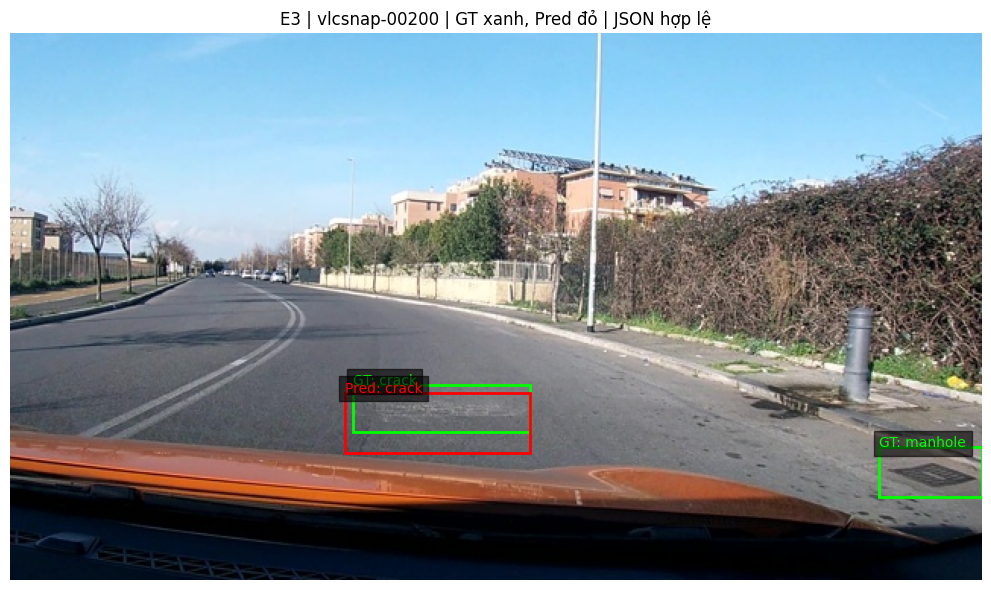

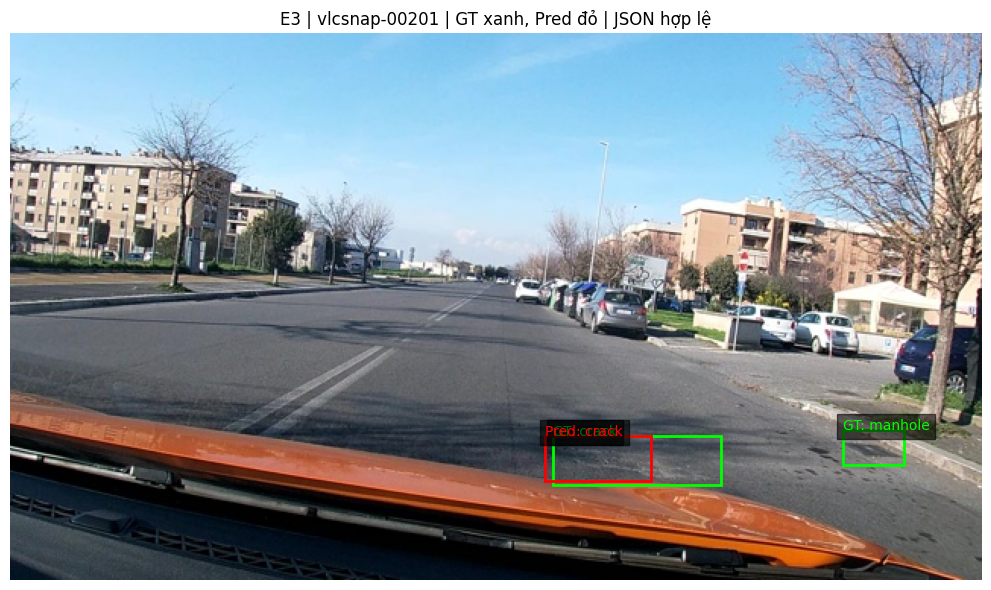

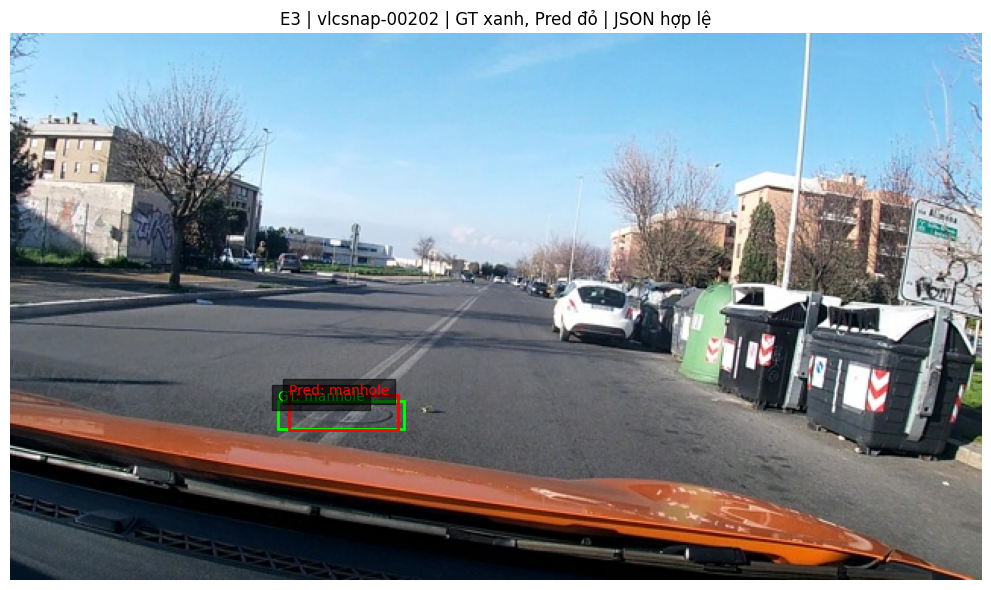

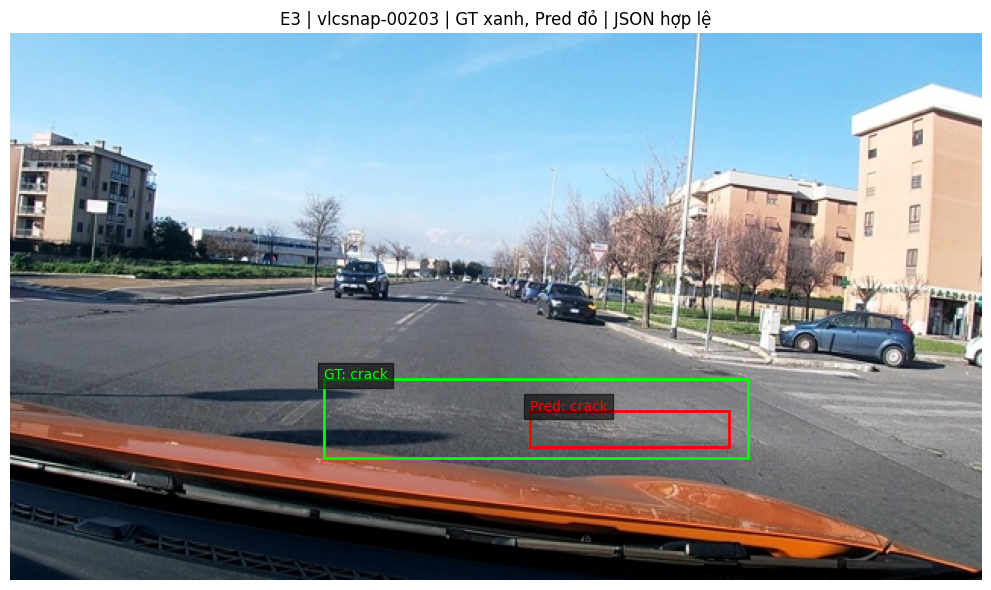

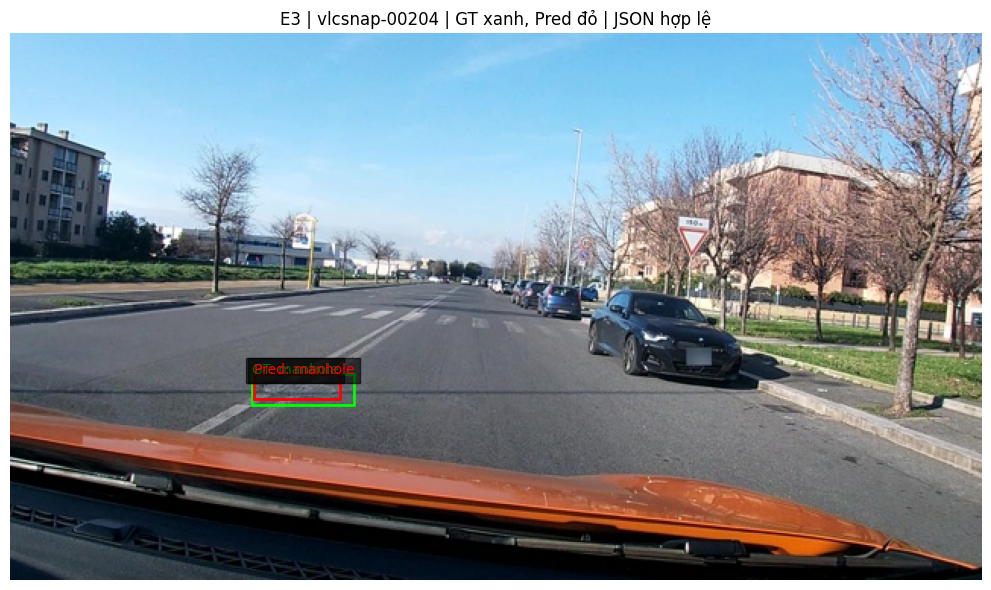

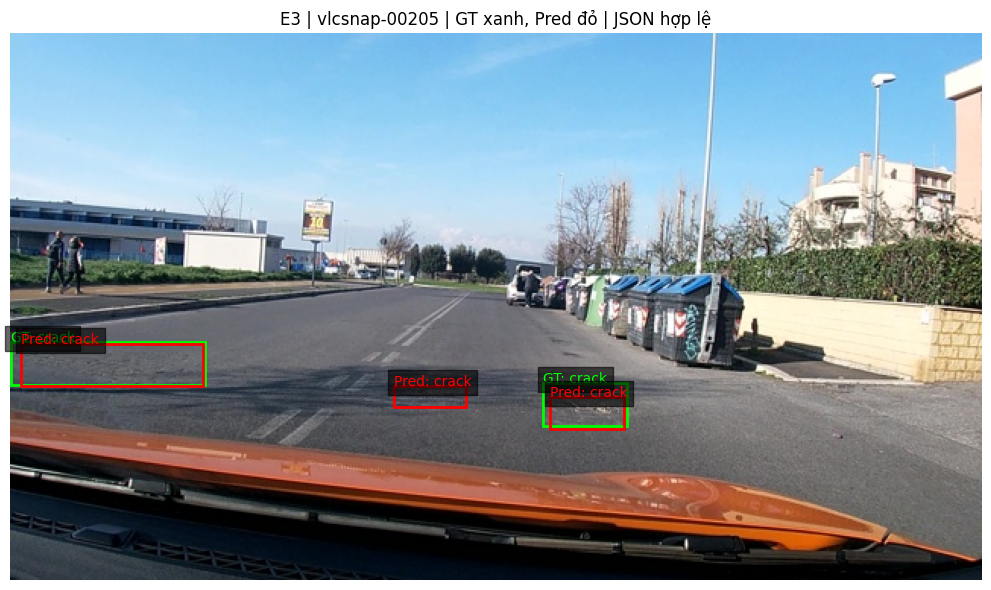

[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[PASS] git commits — 8/5
[PASS] git forbidden files

1 FAIL, 0 WARN
Bài nộp còn FAIL ở trên. Hoàn thiện REPORT.md/lịch sử git sau khi tải evidence thật.


In [30]:
# Bảng số liệu và 6 ảnh dự đoán/GT từ kết quả thật; không điền báo cáo bằng số giả.
from scripts.score import parse_output
from IPython.display import display, Markdown

names = ("E0", "E1", "E2", "E3", "E4_data_size_0.1", "E4_data_size_1.0")
rows = ["| Setup | F1 | CI95 | FP/ảnh | F1 pothole/crack/manhole | VRAM GB | phút |",
        "|---|---:|---|---:|---|---:|---:|"]
for name in names:
    evidence = evidence_for(name)
    per_class = "/".join(f"{evidence['per_class'][label]['f1']:.3f}" for label in CLASSES)
    ci = evidence['f1_ci95']
    metadata = evidence.get('meta', {})
    rows.append(f"| {name} | {evidence['micro']['f1']:.3f} | {ci[0]:.3f}–{ci[1]:.3f} | "
                f"{evidence['fp_per_image']:.3f} | {per_class} | "
                f"{metadata.get('peak_vram_gb', '—')} | {metadata.get('train_minutes', '—')} |")
Path('report/metrics.md').write_text('\n'.join(rows) + '\n', encoding='utf-8')
display(Markdown('\n'.join(rows)))
best = max(("E1", "E2", "E3"), key=lambda name: evidence_for(name)['micro']['f1'])
predictions = {r['image_id']: r['raw'] for r in read_jsonl(f'work/{best.lower()}.jsonl')}
figure_dir = Path('report/figures')
figure_dir.mkdir(parents=True, exist_ok=True)
for index, record in enumerate(test_records[:6]):
    image = Image.open(Path('data') / record['image_path']).convert('RGB')
    figure, axis = plt.subplots(figsize=(12, 6))
    axis.imshow(image)
    truth = [{"label": b['label'], "bbox": b['bbox_2d']}
             for b in json.loads(objects_to_answer(record['objects']))]
    pred = parse_output(predictions[record['image_id']])
    for boxes, color, prefix in ((truth, 'lime', 'GT'), (pred or [], 'red', 'Pred')):
        for box in boxes:
            x1, y1, x2, y2 = box['bbox']
            x1, x2 = x1 * image.width/1000, x2 * image.width/1000
            y1, y2 = y1 * image.height/1000, y2 * image.height/1000
            axis.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                            fill=False, edgecolor=color, linewidth=2))
            axis.text(x1, y1, f"{prefix}: {box['label']}", color=color,
                      bbox=dict(facecolor='black', alpha=0.6))
    axis.set_title(f"{best} | {record['image_id']} | GT xanh, Pred đỏ | JSON {'hợp lệ' if pred is not None else 'hỏng'}")
    axis.axis('off')
    figure.tight_layout()
    figure.savefig(figure_dir / f'example_{index+1}.png', dpi=130)
    plt.show()
    plt.close(figure)

# REPORT.md và lịch sử git là bài nộp cá nhân; hiển thị mọi FAIL thay vì che lỗi.
submission = subprocess.run([sys.executable, 'scripts/check_submission.py'], check=False)
if submission.returncode:
    print('Bài nộp còn FAIL ở trên. Hoàn thiện REPORT.md/lịch sử git sau khi tải evidence thật.')

In [31]:
import zipfile
from IPython.display import FileLink, display

def package_evidence(output_root):
    archive = Path(output_root) / 'lab_day10_evidence.zip'
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as output:
        for file in sorted(Path('report').rglob('*')):
            if file.is_file():
                output.write(file, file.as_posix())
        output.write('data/splits/meta.json', 'data/splits/meta.json')
        for file in sorted(Path('work').rglob('*.json')):
            output.write(file, file.as_posix())
        provenance = {"revision": RUN_REVISION,
                      "notebook_source": "executing imported notebook; retain Kaggle saved version separately",
                      "note": "Remote clone notebook omitted because it may differ from executing code."}
        output.writestr('source_provenance.json', json.dumps(provenance, indent=2))
    return archive

# Kaggle giữ artifact ở /kaggle/working ngay cả khi cwd nằm trong repo clone.
output_root = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
archive = package_evidence(output_root)
print('Evidence, bảng số liệu, ảnh và log:', archive)
print('Mã notebook: giữ riêng bản Save Version đang chạy trên Kaggle, không dùng bản từ repo clone.')
if os.environ.get('COLAB_RELEASE_TAG'):
    from google.colab import files
    files.download(str(archive))
else:
    display(FileLink(os.path.relpath(archive, Path.cwd())))
    print('Trên Kaggle, tải lab_day10_evidence.zip trong Output của phiên chạy.')

Evidence, bảng số liệu, ảnh và log: /kaggle/working/lab_day10_evidence.zip
Mã notebook: giữ riêng bản Save Version đang chạy trên Kaggle, không dùng bản từ repo clone.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>